## Final Year Project Code

**Title :** Personalized Fitness Hybrid-Based Recommender System 

### Import Libraries

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import keras

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder, MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import PCA

import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.layers import Input, Dense, Lambda, Dropout, BatchNormalization
from tensorflow.keras.losses import binary_crossentropy
from tensorflow.keras import backend as K

from scipy.sparse import csr_matrix
from scipy.spatial.distance import cdist
import ast

import os
import pickle

### Load Datasets

In [5]:
member_data = pd.read_csv('gym_members_exercise_tracking_synthetic_data.csv')
program_data = pd.read_csv('programs_detailed_boostcamp_kaggle.csv')

### Data Exploration (Member)

In [7]:
display(member_data.head(5))

,Age,Gender,Weight (kg),Height (m),Max_BPM,Avg_BPM,Resting_BPM,Session_Duration (hours),Calories_Burned,Workout_Type,Fat_Percentage,Water_Intake (liters),Workout_Frequency (days/week),Experience_Level,BMI
0,34.0,Female,86.7,1.86,174,152.0,74.0,1.12,712.0,Strength,12.8,2.4,5.0,2.0,14.31
1,26.0,Female,84.7,1.83,166,156.0,73.0,1.00,833.0,Strength,27.9,2.8,5.0,2.0,33.49
2,22.0,Male,64.8,1.85,187,166.0,64.0,1.24,1678.0,Cardio,28.7,1.9,3.0,2.0,12.73
3,54.0,Female,75.3,1.82,187,169.0,58.0,1.45,628.0,Cardio,31.8,2.4,4.0,1.0,20.37
4,34.0,Female,52.8,1.74,177,169.0,66.0,1.60,1286.0,Strength,26.4,3.2,4.0,2.0,20.83


In [8]:
display(member_data.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1800 entries, 0 to 1799
Data columns (total 15 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Age                            1790 non-null   float64
 1   Gender                         1729 non-null   object 
 2   Weight (kg)                    1778 non-null   float64
 3   Height (m)                     1774 non-null   float64
 4   Max_BPM                        1779 non-null   object 
 5   Avg_BPM                        1770 non-null   float64
 6   Resting_BPM                    1781 non-null   float64
 7   Session_Duration (hours)       1777 non-null   float64
 8   Calories_Burned                1777 non-null   float64
 9   Workout_Type                   1739 non-null   object 
 10  Fat_Percentage                 1784 non-null   float64
 11  Water_Intake (liters)          1776 non-null   float64
 12  Workout_Frequency (days/week)  1742 non-null   f

None

In [9]:
display(member_data.isnull().sum())

Age                              10
Gender                           71
Weight (kg)                      22
Height (m)                       26
Max_BPM                          21
Avg_BPM                          30
Resting_BPM                      19
Session_Duration (hours)         23
Calories_Burned                  23
Workout_Type                     61
Fat_Percentage                   16
Water_Intake (liters)            24
Workout_Frequency (days/week)    58
Experience_Level                 57
BMI                              30
dtype: int64

In [10]:
display('Total duplicates :', member_data.duplicated().sum())

'Total duplicates :'

0

In [11]:
display(member_data.describe())

,Age,Weight (kg),Height (m),Avg_BPM,Resting_BPM,Session_Duration (hours),Calories_Burned,Fat_Percentage,Water_Intake (liters),Workout_Frequency (days/week),Experience_Level,BMI
count,1790.000000,1778.000000,1774.000000,1770.000000,1781.000000,1777.000000,1777.000000,1784.000000,1776.000000,1742.000000,1743.000000,1770.000000
mean,34.475419,67.606637,1.739233,146.259322,63.951151,1.391598,1033.698931,23.509361,2.706644,3.339265,1.823867,19.957774
std,12.315728,19.861408,0.123892,15.219516,7.936502,0.372342,328.049662,5.865557,0.710224,0.947955,0.746568,6.573175
min,18.000000,40.000000,1.500000,120.000000,50.000000,0.500000,303.000000,10.000000,1.500000,2.000000,1.000000,12.320000
25%,23.000000,52.300000,1.650000,133.250000,57.000000,1.130000,794.000000,20.500000,2.100000,3.000000,1.000000,14.780000
50%,33.000000,65.300000,1.730000,146.000000,65.000000,1.370000,1030.000000,24.300000,2.800000,3.000000,2.000000,18.690000
75%,45.000000,80.100000,1.820000,160.000000,72.000000,1.640000,1249.000000,27.500000,3.400000,4.000000,2.000000,23.517500
max,59.000000,129.900000,2.000000,169.000000,74.000000,2.000000,1783.000000,35.000000,3.700000,5.000000,3.000000,49.840000


In [12]:
for col in member_data.columns:
    print(f"{col} ({member_data[col].dtype}) unique values: {member_data[col].unique()}")

Age (float64) unique values: [34. 26. 22. 54. 38. 44. 50. 18. 39. 46. 19. 56. 30. 23. nan 36. 25. 59.
 32. 28. 27. 20. 51. 52. 35. 21. 48. 37. 49. 42. 24. 33. 47. 45. 55. 41.
 29. 43. 57. 31. 53. 58. 40.]
Gender (object) unique values: ['Female' 'Male' nan]
Weight (kg) (float64) unique values: [ 86.7  84.7  64.8  75.3  52.8  53.   46.5  88.5  82.9  65.9  47.   40.
  87.7 107.4  71.7  90.6  56.2  71.3  47.7  63.  129.9 102.4  64.2 129.4
  57.2  71.8 112.4  64.3  72.4  62.4  78.6  45.  103.4  79.2  75.7  76.8
 112.6  73.7  84.   68.  107.6  54.3  42.8  55.4  95.5  58.7  49.7  86.5
  63.6  56.6  67.7  68.3  99.1  72.9  58.3  45.8  52.3  76.3  77.5   nan
  96.3  49.6  86.4  68.4  56.9  51.1  47.6  88.8  67.5  96.7  55.7 112.
  75.2  72.   59.1  41.3  63.7 100.   47.1  72.1  57.5  63.9  68.9  95.3
  84.4  60.5  49.8  47.2  56.3  46.1  69.8  60.6  53.3  95.7  57.4  87.3
  73.8  66.3  72.8  50.   93.5  55.3  66.6  65.8  59.8  80.3  91.7  60.1
  59.   46.3  66.9  79.   50.1  66.8  53.9  97.1  

### Data Exploration (Program)

In [14]:
display(program_data.head(5))

,title,description,level,goal,equipment,program_length,time_per_workout,week,day,number_of_exercises,exercise_name,sets,reps,intensity,created,last_edit
0,Weightlifting Mobility program,This program is designed to help athletes succ...,"['Beginner', 'Novice', 'Intermediate', 'Advanc...","['Olympic Weightlifting', 'Muscle & Sculpting'...",Garage Gym,7.0,50.0,1.0,1.0,16.0,Knee-to-wall ankle dorsiflexion test,3.0,-180.0,6.0,2025-03-09 04:11:00,2025-06-23 03:31:00
1,Weightlifting Mobility program,This program is designed to help athletes succ...,"['Beginner', 'Novice', 'Intermediate', 'Advanc...","['Olympic Weightlifting', 'Muscle & Sculpting'...",Garage Gym,7.0,50.0,1.0,1.0,16.0,Banded ankle distractions,3.0,-18.0,6.0,2025-03-09 04:11:00,2025-06-23 03:31:00
2,Weightlifting Mobility program,This program is designed to help athletes succ...,"['Beginner', 'Novice', 'Intermediate', 'Advanc...","['Olympic Weightlifting', 'Muscle & Sculpting'...",Garage Gym,7.0,50.0,1.0,1.0,16.0,Slant board calf stretch,3.0,-18.0,6.0,2025-03-09 04:11:00,2025-06-23 03:31:00
3,Weightlifting Mobility program,This program is designed to help athletes succ...,"['Beginner', 'Novice', 'Intermediate', 'Advanc...","['Olympic Weightlifting', 'Muscle & Sculpting'...",Garage Gym,7.0,50.0,1.0,1.0,16.0,Seated Tibialis Raise,3.0,15.0,6.0,2025-03-09 04:11:00,2025-06-23 03:31:00
4,Weightlifting Mobility program,This program is designed to help athletes succ...,"['Beginner', 'Novice', 'Intermediate', 'Advanc...","['Olympic Weightlifting', 'Muscle & Sculpting'...",Garage Gym,7.0,50.0,1.0,1.0,16.0,90/90 Hip Rotations,3.0,8.0,6.0,2025-03-09 04:11:00,2025-06-23 03:31:00


In [15]:
display(program_data.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 605033 entries, 0 to 605032
Data columns (total 16 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   title                605033 non-null  object 
 1   description          604214 non-null  object 
 2   level                605033 non-null  object 
 3   goal                 605033 non-null  object 
 4   equipment            605017 non-null  object 
 5   program_length       605017 non-null  float64
 6   time_per_workout     605033 non-null  float64
 7   week                 605033 non-null  float64
 8   day                  605033 non-null  float64
 9   number_of_exercises  605033 non-null  float64
 10  exercise_name        605033 non-null  object 
 11  sets                 605033 non-null  float64
 12  reps                 605033 non-null  float64
 13  intensity            605033 non-null  float64
 14  created              605017 non-null  object 
 15  last_edit        

None

In [16]:
display(program_data.isnull().sum())

title                    0
description            819
level                    0
goal                     0
equipment               16
program_length          16
time_per_workout         0
week                     0
day                      0
number_of_exercises      0
exercise_name            0
sets                     0
reps                     0
intensity                0
created                 16
last_edit               41
dtype: int64

In [17]:
display('Total duplicates :', program_data.duplicated().sum())

'Total duplicates :'

904

In [18]:
display(program_data.describe())

,program_length,time_per_workout,week,day,number_of_exercises,sets,reps,intensity
count,605017.000000,605033.000000,605033.000000,605033.000000,605033.000000,605033.000000,605033.000000,605033.000000
mean,10.933861,72.255351,5.929030,2.812116,6.846263,2.606160,-23.953452,7.868779
std,3.789097,24.282719,3.821923,1.480664,2.739406,1.145656,746.027461,1.205327
min,1.000000,10.000000,1.000000,1.000000,1.000000,1.000000,-86400.000000,0.000000
25%,8.000000,60.000000,3.000000,2.000000,5.000000,2.000000,8.000000,7.000000
50%,12.000000,70.000000,5.000000,3.000000,6.000000,3.000000,10.000000,8.000000
75%,12.000000,90.000000,8.000000,4.000000,8.000000,3.000000,12.000000,9.000000
max,18.000000,180.000000,18.000000,10.000000,24.000000,30.000000,200.000000,10.000000


In [19]:
for col in program_data.columns:
    print(f"{col} ({program_data[col].dtype}) unique values: {program_data[col].unique()}")

title (object) unique values: ['Weightlifting Mobility program'
 'Lyle McDonald Routine (Strength/Hypertrophy Vers)'
 'Jeff Nippard’s Fundamentals, Upper&Lower Split, 4x' ...
 'Smolov Jr Bench Press Program' '531 HARDCORE' 'Matt Vena modified']
description (object) unique values: ['This program is designed to help athletes succeed in building their mobility and core in all areas.'
 'IMPORTANT: THIS IS NOT THE ORIGINAL LYLE MCDONALD\'S SCHEDULE. THIS IS THE SCHEDULE THAT DESIGNED BY A USER WITH BASING LYLE MCDONALD\'S SCHEDULE. BUT ALSO THIS SCHEDULE IS VERY SIMILAR TO LYLE MCDONALD\'S SCHEDULE AND THE DESCRIPTION WHICH IN THE BELOW IS WROTE BY LYLE MCDONALD AND LIFT VAULT. IF YOU WANT TO LOOK ORIGINAL PROGRAM YOU CAN VISIT THE LIFT VAULT WEBSITE.\nTHANK YOU!\n\nLyle McDonald’s generic bulking routine allows for a lot of flexibility within the program. If you are not comfortable with making some decisions within your training, then this program may not be for you. Alternatively, this ma

### Data Cleaning & Data Preprocessing (Member)

In [21]:
member_clean = member_data.copy()

# Remove \\n and \\t in front some the values
for col in member_clean.columns:
    if member_clean[col].dtype == 'object':
        member_clean[col] = member_clean[col].str.replace(r'\\n', '', regex=True)
        member_clean[col] = member_clean[col].str.replace(r'\\t', '', regex=True)

num_cols = member_clean.select_dtypes(include='number').columns
member_clean[num_cols] = member_clean[num_cols].fillna(member_clean[num_cols].median())
member_clean = member_clean.dropna()
member_clean = member_clean.drop_duplicates()

member_clean['Age'] = member_clean['Age'].astype(int)
member_clean['Max_BPM'] = member_clean['Max_BPM'].astype(int)
member_clean['Avg_BPM'] = member_clean['Avg_BPM'].astype(int)
member_clean['Resting_BPM'] = member_clean['Resting_BPM'].astype(int)
member_clean['Calories_Burned'] = member_clean['Calories_Burned'].astype(int)
member_clean['Workout_Frequency (days/week)'] = member_clean['Workout_Frequency (days/week)'].astype(int)
member_clean['Experience_Level'] = member_clean['Experience_Level'].astype(int)

member_clean['User_ID'] = range(1, len(member_clean) + 1)

label_encoders = {}
categorical_col = ['Gender', 'Workout_Type']

# Convert categorical values -> numerical values (Better for training model)
for col in categorical_col:
    le = LabelEncoder()
    member_clean[f'{col}_Encoded'] = le.fit_transform(member_clean[col])
    label_encoders[col] = le

member_clean['BMI_Group'] = pd.cut(member_clean['BMI'], bins = [0, 18.5, 25, 30, 100], labels = ['Underweight', 'Normal', 'Overweight', 'Obese'])
member_clean['Fitness_Score'] = (member_clean['Workout_Frequency (days/week)'] * 0.3 + member_clean['Session_Duration (hours)'] * 0.2 + (member_clean['Calories_Burned'] / 1000) * 0.3 + member_clean['Experience_Level'] * 0.2)

display(member_clean.head())
print(f"Cleaned Gym Members Dataset Shape: {member_clean.shape}")
print(f"Number of users: {member_clean['User_ID'].nunique()}")

,Age,Gender,Weight (kg),Height (m),Max_BPM,Avg_BPM,Resting_BPM,Session_Duration (hours),Calories_Burned,Workout_Type,Fat_Percentage,Water_Intake (liters),Workout_Frequency (days/week),Experience_Level,BMI,User_ID,Gender_Encoded,Workout_Type_Encoded,BMI_Group,Fitness_Score
0,34,Female,86.7,1.86,174,152,74,1.12,712,Strength,12.8,2.4,5,2,14.31,1,0,2,Underweight,2.3376
1,26,Female,84.7,1.83,166,156,73,1.00,833,Strength,27.9,2.8,5,2,33.49,2,0,2,Obese,2.3499
2,22,Male,64.8,1.85,187,166,64,1.24,1678,Cardio,28.7,1.9,3,2,12.73,3,1,0,Underweight,2.0514
3,54,Female,75.3,1.82,187,169,58,1.45,628,Cardio,31.8,2.4,4,1,20.37,4,0,0,Normal,1.8784
4,34,Female,52.8,1.74,177,169,66,1.60,1286,Strength,26.4,3.2,4,2,20.83,5,0,2,Normal,2.3058


Cleaned Gym Members Dataset Shape: (1652, 20)
Number of users: 1652


### Data Cleaning & Data Preprocessing (Program)

In [23]:
program_clean = program_data.copy()

num_cols = program_clean.select_dtypes(include='number').columns
program_clean[num_cols] = program_clean[num_cols].fillna(program_clean[num_cols].median())
program_clean = program_clean.dropna()
program_clean = program_clean.drop_duplicates()

program_clean['program_length'] = program_clean['program_length'].astype(int)
program_clean['time_per_workout'] = program_clean['time_per_workout'].astype(int)
program_clean['week'] = program_clean['week'].astype(int)
program_clean['day'] = program_clean['day'].astype(int)
program_clean['number_of_exercises'] = program_clean['number_of_exercises'].astype(int)
program_clean['sets'] = program_clean['sets'].astype(int)
program_clean['intensity'] = program_clean['intensity'].astype(int)

# Convert string -> list 
def safe_parse_list(val):
    if isinstance(val, str):
        try:
            return ast.literal_eval(val)
        except (ValueError, SyntaxError):
            return []
    return val if isinstance(val, list) else []

program_clean['level_list'] = program_clean['level'].apply(safe_parse_list)
program_clean['goal_list'] = program_clean['goal'].apply(safe_parse_list)

# Select first element of all the list
program_clean['primary_level'] = program_clean['level_list'].apply(lambda x: x[0] if len(x) > 0 else 'Intermediate')
program_clean['primary_goal'] = program_clean['goal_list'].apply(lambda x: x[0] if len(x) > 0 else 'Bodybuilding')

# Convert categorical -> numerical
le_level = LabelEncoder()
le_goal = LabelEncoder()
program_clean['level_encoded'] = le_level.fit_transform(program_clean['primary_level'])
program_clean['goal_encoded'] = le_goal.fit_transform(program_clean['primary_goal'])

# Group by data with similar title and used the first row of data for each title
# To reduce the number of programs for better user-item matrix interaction generation
program_clean = program_clean.groupby('title').agg({
    'description': 'first',
    'primary_level': 'first',
    'primary_goal': 'first',
    'equipment': 'first',
    'program_length': 'first',
    'time_per_workout': 'first',
    'number_of_exercises': 'mean',
    'sets': 'mean',
    'level_encoded': 'first',
    'goal_encoded': 'first'
}).reset_index()

program_clean['number_of_exercises'] = np.floor(program_clean['number_of_exercises']).astype(int)
program_clean['sets'] = np.floor(program_clean['sets']).astype(int)
program_clean['Program_ID'] = range(1, len(program_clean) + 1)

display(program_clean.head())
print(f"Cleaned Programs Dataset Shape: {program_clean.shape}")
print(f"Number of unique programs: {program_clean['Program_ID'].nunique()}")

,title,description,primary_level,primary_goal,equipment,program_length,time_per_workout,number_of_exercises,sets,level_encoded,goal_encoded,Program_ID
0,(MASS MONSTER) High Intensity 4 Day Upper Lowe...,Build tones of muscular with this high intensi...,Intermediate,Muscle & Sculpting,Full Gym,12,90,6,1,2,4,1
1,(NOT MY PROGRAM)SHJ Jotaro,Build strength and size,Advanced,Bodybuilding,Full Gym,8,60,7,3,0,2,2
2,1 PowerLift Per Day Powerbuilding 5 Day Bro Split,Based off of Andy Baker's KCS (Kingwood Streng...,Beginner,Athletics,Full Gym,6,90,7,2,1,1,3
3,10 Week Mass Building Program,This workout is designed to increase your musc...,Intermediate,Powerbuilding,Garage Gym,10,70,7,2,2,6,4
4,10 week deadlift focus,Increase deadlift,Intermediate,Powerbuilding,Full Gym,10,80,7,3,2,6,5


Cleaned Programs Dataset Shape: (2592, 12)
Number of unique programs: 2592


### Exploratory Data Analysis

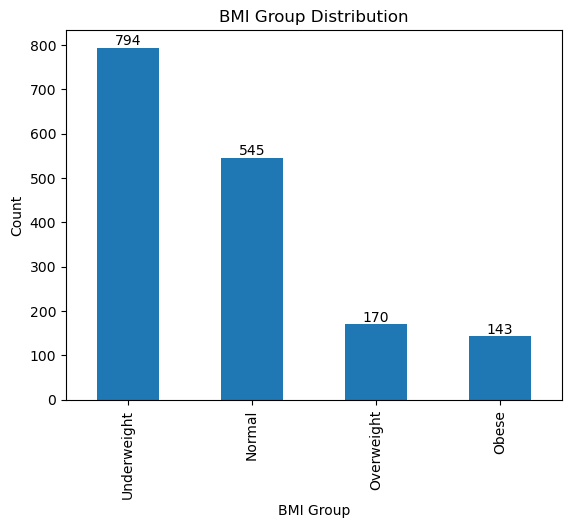

In [25]:
plt.figure()
bg = member_clean['BMI_Group'].value_counts().plot(kind='bar')
plt.title('BMI Group Distribution')
plt.xlabel('BMI Group')
plt.ylabel('Count')
bg.bar_label(bg.containers[0])
plt.show()

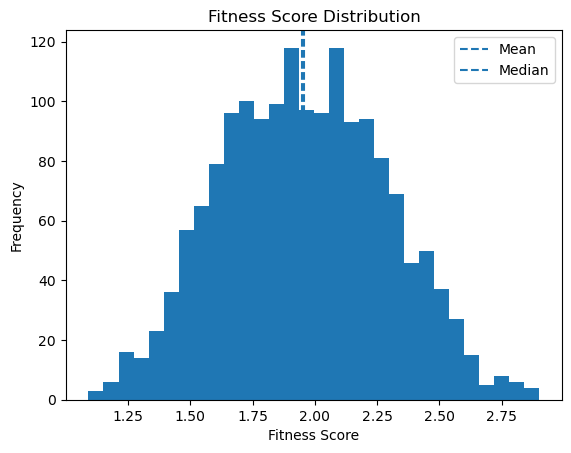

In [26]:
plt.figure()
plt.hist(member_clean['Fitness_Score'], bins=30)
plt.axvline(member_clean['Fitness_Score'].mean(), linestyle='--', label='Mean')
plt.axvline(member_clean['Fitness_Score'].median(), linestyle='--', label='Median')
plt.title('Fitness Score Distribution')
plt.xlabel('Fitness Score')
plt.ylabel('Frequency')
plt.legend()
plt.show()

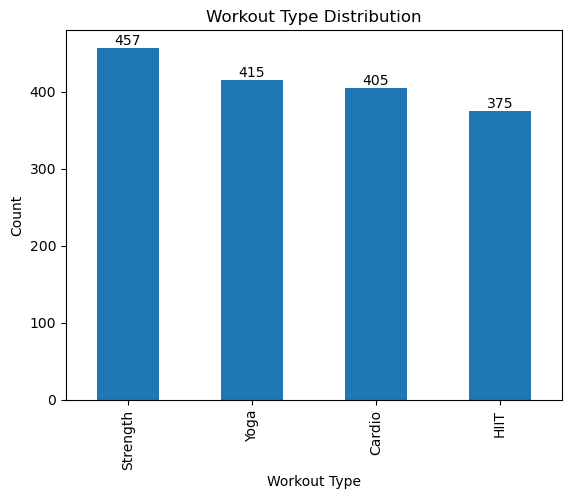

In [27]:
plt.figure()
wt = member_clean['Workout_Type'].value_counts().plot(kind = 'bar')
plt.title('Workout Type Distribution')
plt.xlabel('Workout Type')
plt.ylabel('Count')
wt.bar_label(wt.containers[0])
plt.show()

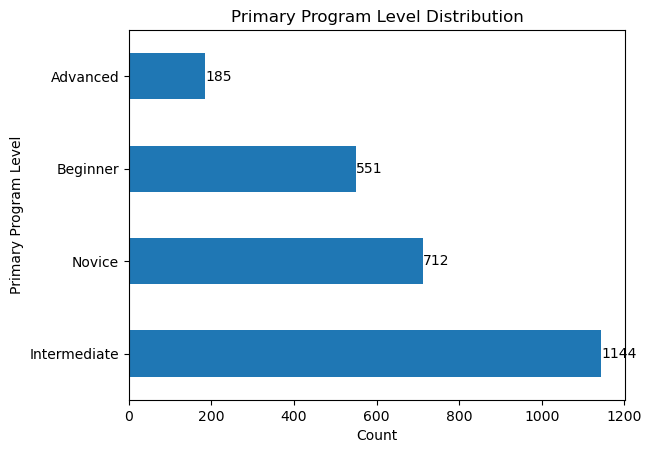

In [28]:
plt.figure()
ppl = program_clean['primary_level'].value_counts().plot(kind = 'barh')
plt.title('Primary Program Level Distribution')
plt.xlabel('Count')
plt.ylabel('Primary Program Level')
ppl.bar_label(ppl.containers[0])
plt.show()

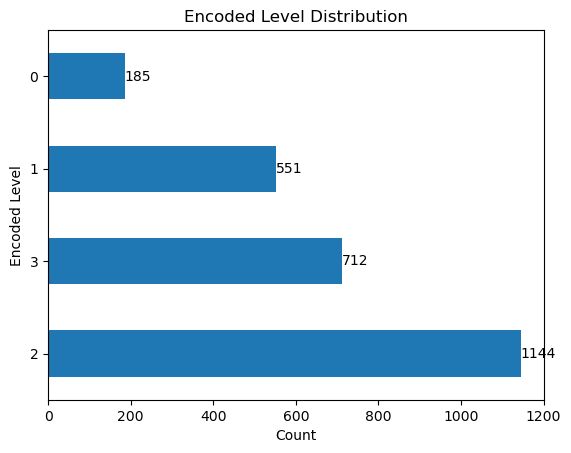

In [29]:
plt.figure()
ppl = program_clean['level_encoded'].value_counts().plot(kind = 'barh')
plt.title('Encoded Level Distribution')
plt.xlabel('Count')
plt.ylabel('Encoded Level')
ppl.bar_label(ppl.containers[0])
plt.show()

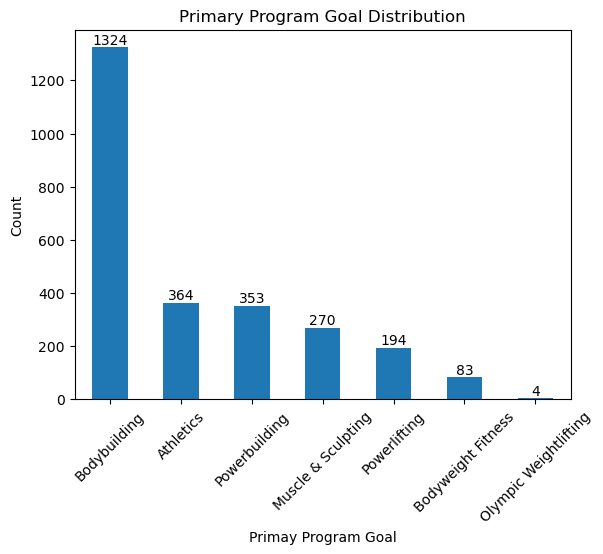

In [30]:
plt.figure()
ppg = program_clean['primary_goal'].value_counts().plot(kind = 'bar')
plt.title('Primary Program Goal Distribution')
plt.xlabel('Primay Program Goal')
plt.ylabel('Count')
plt.xticks(rotation=45)
ppg.bar_label(ppg.containers[0])
plt.show()

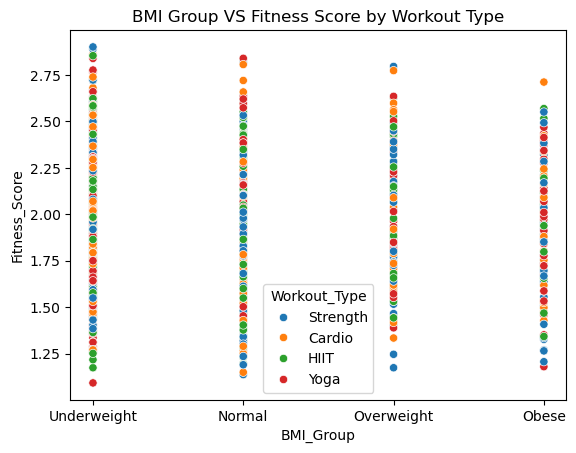

In [31]:
plt.figure()
sns.scatterplot(data = member_clean, x = 'BMI_Group', y = 'Fitness_Score', hue = 'Workout_Type')
plt.title('BMI Group VS Fitness Score by Workout Type')
plt.show()

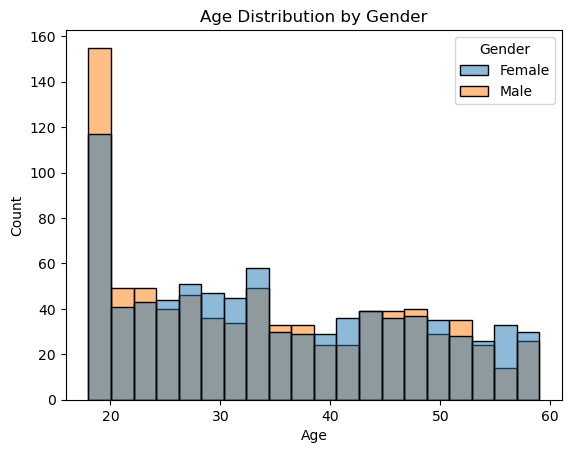

In [32]:
plt.figure()
sns.histplot(data = member_clean, x = 'Age', hue = 'Gender', bins = 20)
plt.title('Age Distribution by Gender')
plt.show()

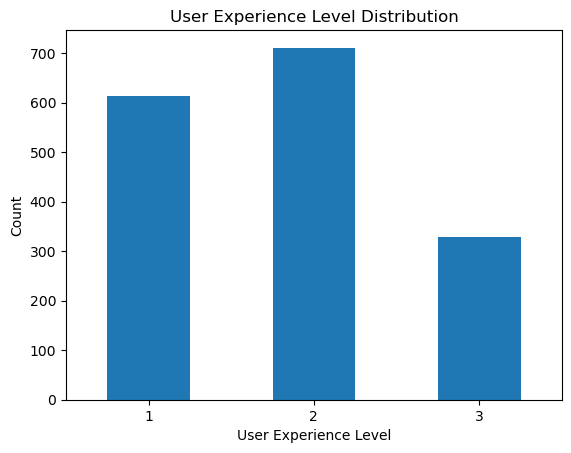

In [33]:
plt.figure()
member_clean['Experience_Level'].value_counts().sort_index().plot(kind = 'bar')
plt.title('User Experience Level Distribution')
plt.xlabel('User Experience Level')
plt.ylabel('Count')
plt.xticks(rotation = 0)
plt.show()

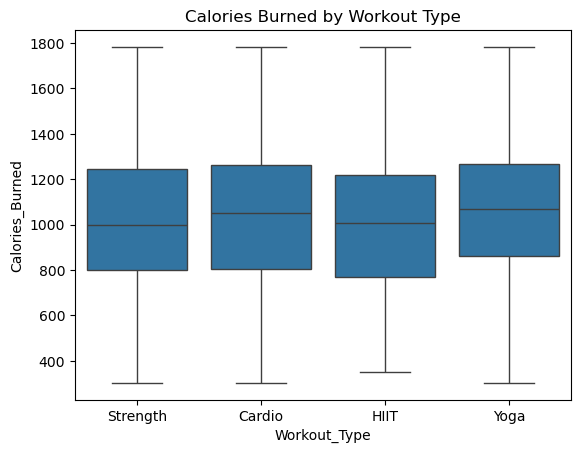

In [34]:
plt.figure()
sns.boxplot(data = member_clean, x = 'Workout_Type', y = 'Calories_Burned')
plt.title('Calories Burned by Workout Type')
plt.show()

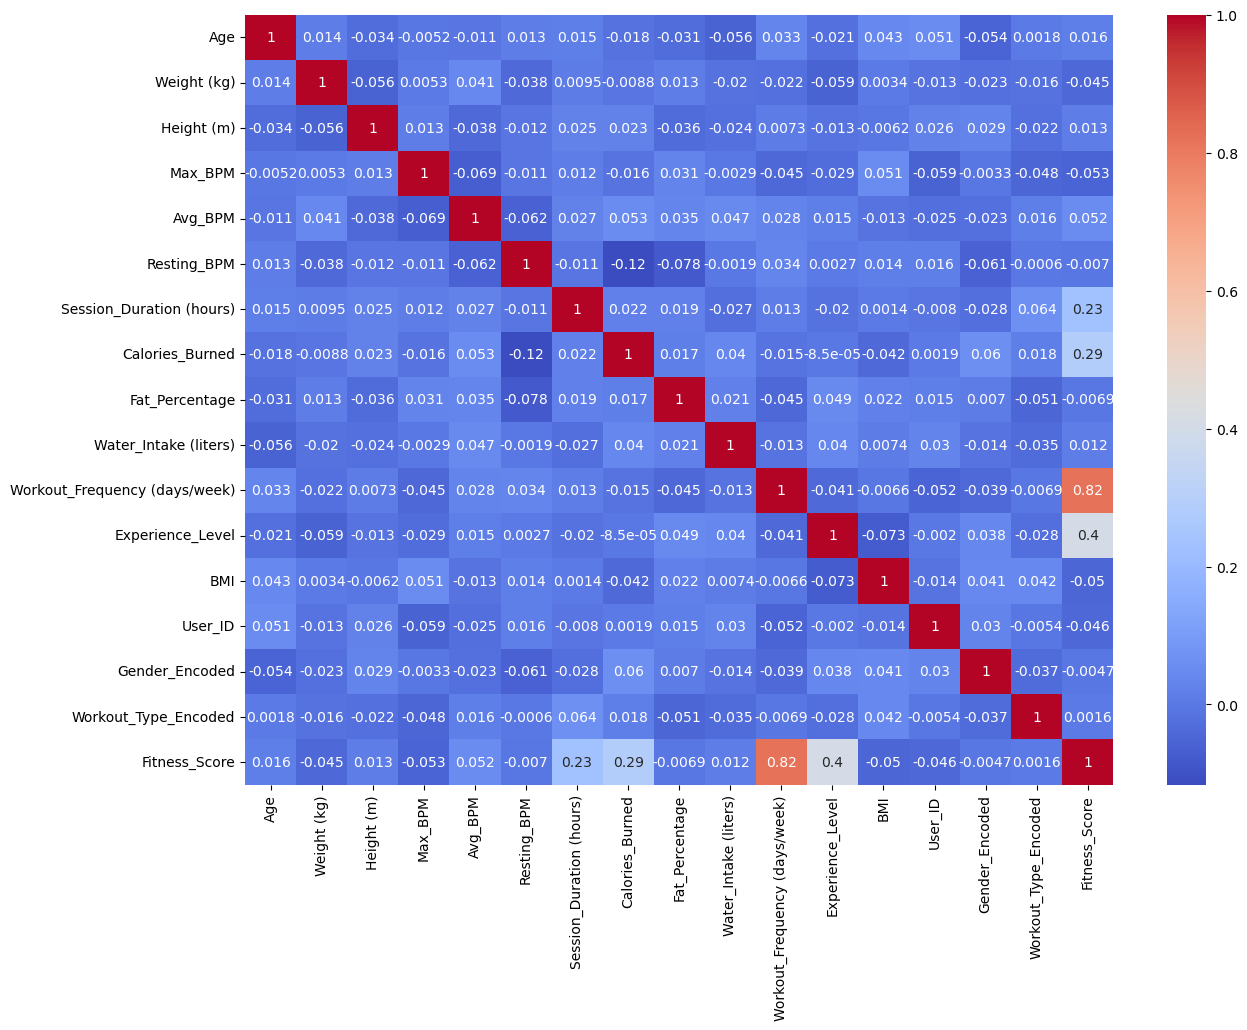

In [35]:
member_num = member_clean.select_dtypes(include = 'number')
member_corr = member_num.corr()

plt.figure(figsize = (14, 10))
sns.heatmap(member_corr, annot = True, cmap = 'coolwarm')
plt.show()

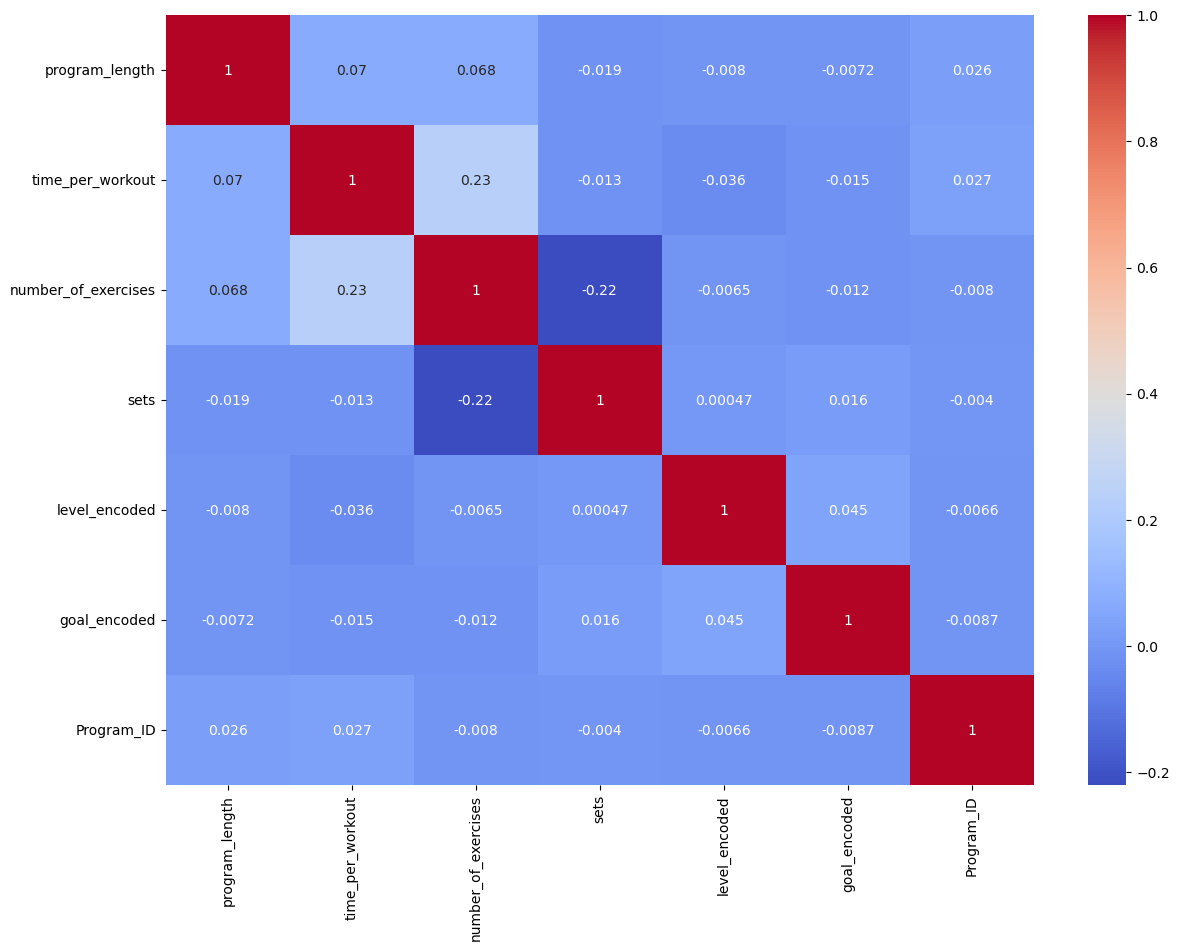

In [36]:
program_num = program_clean.select_dtypes(include = 'number')
program_corr = program_num.corr()

plt.figure(figsize = (14, 10))
sns.heatmap(program_corr, annot = True, cmap = 'coolwarm')
plt.show()

### Create User-Item Interaction Matrix

In [38]:
# Create a workout type map to primary goal list
workout_to_goal = {
    'Strength' : ['Bodybuilding', 'Powerlifting', 'Powerbuilding', 'Muscle & Sculpting', 'Olympic Weightlifting'],
    'Cardio' : ['Athletics', 'Bodyweight Fitness'],
    'HIIT' : ['Athletics', 'Muscle & Sculpting', 'At-home & Calisthenics'],
    'Yoga' : ['Bodyweight Fitness']
}

In [39]:
interaction = []

for idx, user in member_clean.iterrows():
    workout_type = user['Workout_Type']
    experience_level = user['Experience_Level']

    goal = workout_to_goal.get(workout_type)
    program = program_clean[program_clean['primary_goal'].isin(goal)]

    # Get 3 to 5 number of interactions for each user
    # Then it will give the following number of programs for user 
    num_interaction = np.random.randint(3, 6)
    n = min(num_interaction , len(program))
    sample_program = program.sample(n, replace = False)

    # Generate random ratings from 3 to 5 for each sample programs
    for _, prog in sample_program.iterrows():
        rating = np.random.uniform(3, 5)

        # Check if the program's program level given is close to the user's experience level
        # If the level is a match from 0 to 1 range then the rating will be increase randomly by 1
        level_match = abs(experience_level - prog['level_encoded']) <= 1
        if level_match:
            rating += np.random.uniform(0, 1)

        # To make sure that program with 5 rating wont exceed 5 after its a matched for fitness level
        rating = min(5, rating)

        # Store the produced interactions
        interaction.append({
            'User_ID' : user['User_ID'],
            'Program_ID' : prog['Program_ID'],
            'Rating' : rating,
            'Workout_Type' : workout_type,
            'Experience_Level' : experience_level
        })

In [40]:
# Convert interaction list into dataframe
interactions_df = pd.DataFrame(interaction)
display(len(interactions_df))
display(interactions_df.head())

6614

,User_ID,Program_ID,Rating,Workout_Type,Experience_Level
0,1,1432,3.505051,Strength,2
1,1,2067,3.156291,Strength,2
2,1,1459,3.814998,Strength,2
3,1,1634,4.865680,Strength,2
4,1,2020,4.357080,Strength,2


In [41]:
# Create a pivot table for each user's interaction with each program
user_item_matrix = interactions_df.pivot_table(
    index = 'User_ID',
    columns = 'Program_ID',
    values = 'Rating',
    fill_value = 0
)

display(user_item_matrix.shape)
display(user_item_matrix.head())

(1652, 1754)

Program_ID,1,2,3,6,7,8,9,10,11,12,...,2578,2580,2581,2583,2585,2586,2587,2589,2590,2591
User_ID,,,,,,,,,,,,,,,,,,,,,
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


### Collaborative Filtering

In [43]:
# Create a class for collaborative filtering
class CollaborativeFiltering:
    def __init__(self, n_neighbors = 5):
        self.n_neighbors = n_neighbors
        self.user_similarity = None
        self.item_similarity = None

    # Calculate user-user similarity and item-item similarity using cosine similarity function
    def fit(self, user_item_matrix):
        self.user_similarity = cosine_similarity(user_item_matrix)
        self.item_similarity = cosine_similarity(user_item_matrix.T)
        self.user_item_matrix = user_item_matrix
        self.user_index_map = {uid : i for i, uid in enumerate(user_item_matrix.index)}
        self.program_index_map = {pid : i for i, pid in enumerate(user_item_matrix.columns)}

    # User-based collaborative filtering
    def predict_user_based(self, user_id, program_id, k = 5):
        if user_id not in self.user_item_matrix.index or program_id not in self.user_item_matrix.columns:
            return 3.0

        # Get user index and program index
        user_index = list(self.user_item_matrix.index).index(user_id)
        program_index = list(self.user_item_matrix.columns).index(program_id)

        # Get user's with high similarity to chosen user
        user_similarities = self.user_similarity[user_index]
        similar_users_index = np.argsort(user_similarities)[::-1][1:k+1]

        ratings = []
        weights = []

        # Check if similar users have interact with the program before
        # Sum up the rating they given for this program if interacted
        for idx in similar_users_index:
            rating = self.user_item_matrix.iloc[idx, program_index]
            if rating > 0 and user_similarities[idx] > 0:
                ratings.append(rating)
                weights.append(user_similarities[idx])

        if len(ratings) == 0 or sum(weights) == 0:
            return 3.0

        # Return weighted average
        return np.average(ratings, weights = weights)

    # Item-based collaborative filtering
    def predict_item_based(self, user_id, program_id, k = 5):
        if user_id not in self.user_item_matrix.index or program_id not in self.user_item_matrix.columns:
            return 3.0

        user_index = list(self.user_item_matrix.index).index(user_id)
        program_index = list(self.user_item_matrix.columns).index(program_id)

        item_similarities = self.item_similarity[program_index]
        similar_items_index = np.argsort(item_similarities)[::-1][1:k+1]

        ratings = []
        weights = []

        for idx in similar_items_index:
            rating = self.user_item_matrix.iloc[user_index, idx]
            if rating > 0 and item_similarities[idx] > 0:
                ratings.append(rating)
                weights.append(item_similarities[idx])

        if len(ratings) == 0 or sum(weights) == 0:
            return 3.0

        return np.average(ratings, weights = weights)

    # Recommendation feature
    def recommend(self, user_id, n_recommendations = 5, method = 'hybrid'):
        if user_id not in self.user_item_matrix.index:
            return []

        # Get user's index and ratings for all existing programs
        user_index = list(self.user_item_matrix.index).index(user_id)
        user_ratings = self.user_item_matrix.iloc[user_index]

        unrated_programs = user_ratings[user_ratings == 0].index.tolist()

        # Get rating's prediction using chosen method
        predictions = []
        for program_id in unrated_programs:
            if method == 'user':
                pred = self.predict_user_based(user_id, program_id)
            elif method == 'item':
                pred = self.predict_item_based(user_id, program_id)
            else:
                pred_user = self.predict_user_based(user_id, program_id)
                pred_item = self.predict_item_based(user_id, program_id)
                pred = (pred_user + pred_item) / 2

            predictions.append((program_id, pred))

        # Sort the recommendations based on highest predicted rating score to lowest
        predictions.sort(key = lambda x: x[1], reverse = True)
        return predictions[:n_recommendations]

In [44]:
# Choose 5 recommendations and fit the model with user-item matrix
cf_model = CollaborativeFiltering(n_neighbors = 5)
cf_model.fit(user_item_matrix)

In [45]:
test_user_id = member_clean['User_ID'].iloc[0]
cf_recommendations = cf_model.recommend(test_user_id, n_recommendations = 5, method = 'hybrid')

print('Top 5 Collaborative Filtering Recommendations for User' + str(test_user_id))
for program_id, score in cf_recommendations:
    program_info = program_clean[program_clean['Program_ID'] == program_id].iloc[0]
    print('Program : ' + program_info['title'][:50] +  ' | Score : ' + f'{score:.2f}')

Top 5 Collaborative Filtering Recommendations for User1
Program : Harambe | Score : 4.16
Program : 2 Day Ultra Busy Split: Arms, Legs, Core Focus | Score : 4.09
Program : 3 Day full body + 1 day arms | Score : 3.81
Program : Tank Maxxing (Upper Lower) | Score : 3.26
Program : (MASS MONSTER) High Intensity 4 Day Upper Lower Pr | Score : 3.00


### Content-Based Filtering

In [47]:
class ContentBasedFiltering:
    def __init__(self):
        self.user_profiles = None
        self.program_features = None
        self.scaler = StandardScaler()

    def fit(self, users_df, programs_df, interactions_df):
        program_feature_cols = ['level_encoded', 'goal_encoded', 'program_length', 'time_per_workout', 'number_of_exercises', 'sets']
        self.program_features = programs_df[['Program_ID'] + program_feature_cols].copy()

        feature_matrix = self.program_features[program_feature_cols].values
        feature_matrix_scaled = self.scaler.fit_transform(feature_matrix)
        self.program_features[program_feature_cols] = feature_matrix_scaled

        self.user_profiles = {}

        for user_id in users_df['User_ID']:
            user_interactions = interactions_df[interactions_df['User_ID'] == user_id]

            if len(user_interactions) > 0:
                weighted_features = np.zeros(len(program_feature_cols))
                total_weight = 0

                for _, interaction in user_interactions.iterrows():
                    program_id = interaction['Program_ID']
                    rating = interaction['Rating']

                    program_features = self.program_features[self.program_features['Program_ID'] == program_id][program_feature_cols].values

                    if len(program_features) > 0:
                        weighted_features += program_features[0] * rating
                        total_weight += rating

                if total_weight > 0:
                    self.user_profiles[user_id] = weighted_features / total_weight
                else:
                    self.user_profiles[user_id] = np.zeros(len(program_feature_cols))
            else:
                self.user_profiles[user_id] = np.zeros(len(program_feature_cols))

    def predict(self, user_id, program_id):
        if user_id not in self.user_profiles:
            return 3.0

        user_profile = self.user_profiles[user_id]
        program_features = self.program_features[self.program_features['Program_ID'] == program_id]

        if len(program_features) == 0:
            return 3.0

        program_feature_cols = ['level_encoded', 'goal_encoded', 'program_length', 'time_per_workout', 'number_of_exercises', 'sets']
        program_vector = program_features[program_feature_cols].values[0]

        similarity = np.dot(user_profile, program_vector) / (np.linalg.norm(user_profile) * np.linalg.norm(program_vector) + 1e-8)

        rating = 3.0 + (similarity * 2.0)
        return max(1.0, min(5.0, rating))

    def recommend(self, user_id, programs_df, interactions_df, n_recommendations = 5):
        if user_id not in self.user_profiles:
            return []

        user_interactions = interactions_df[interactions_df['User_ID'] == user_id]['Program_ID'].tolist()
        unrated_programs = programs_df[~programs_df['Program_ID'].isin(user_interactions)]['Program_ID'].tolist()

        predictions = []
        for program_id in unrated_programs:
            pred = self.predict(user_id, program_id)
            predictions.append((program_id, pred))

        predictions.sort(key = lambda x: x[1], reverse = True)
        return predictions[:n_recommendations]

In [48]:
cbf_model = ContentBasedFiltering()
cbf_model.fit(member_clean, program_clean, interactions_df)

In [49]:
cbf_recommendations = cbf_model.recommend(test_user_id, program_clean, interactions_df, n_recommendations = 5)

print('Top 5 Content Based Filtering Recommendations for User' + str(test_user_id))
for program_id, score in cbf_recommendations:
    program_info = program_clean[program_clean['Program_ID'] == program_id].iloc[0]
    print('Program : ' + program_info['title'][:50] +  ' | Score : ' + f'{score:.2f}')

Top 5 Content Based Filtering Recommendations for User1
Program : Alex Leonidas Novice Program (AlphaDestiny) | Score : 4.93
Program : DEADLIFT PEAKING PROGRAM | Score : 4.91
Program : Only for chad | Score : 4.90
Program : Warrior | Score : 4.90
Program : Simple PPLUL | Score : 4.88


## Variational Autoencoder (VAE)

In [51]:
class Sampling(keras.layers.Layer):
    def call(self, inputs):
        z_mean, z_log_var = inputs
        epsilon = tf.random.normal(shape=tf.shape(z_mean))
        return z_mean + tf.exp(0.5 * z_log_var) * epsilon


class VAEModel(keras.Model):
    def __init__(self, encoder, decoder, input_dim, **kwargs):
        super().__init__(**kwargs)
        self.encoder   = encoder
        self.decoder   = decoder
        self.input_dim = input_dim

    def _masked_recon_loss(self, x, reconstruction):
        # Element-wise BCE
        recon_loss_per_element = -(
            x * tf.math.log(reconstruction + 1e-8) +
            (1 - x) * tf.math.log(1 - reconstruction + 1e-8)
        )

        mask = tf.cast(tf.not_equal(x, 0), dtype=tf.float32)
        masked_loss = recon_loss_per_element * mask
        return tf.reduce_mean(tf.reduce_sum(masked_loss, axis=-1))

    def train_step(self, data):
        if isinstance(data, tuple):
            x = data[0]
        else:
            x = data

        with tf.GradientTape() as tape:
            z_mean, z_log_var, z = self.encoder(x, training=True)
            reconstruction       = self.decoder(z, training=True)

            recon_loss = self._masked_recon_loss(x, reconstruction)

            kl_loss = -0.5 * tf.reduce_mean(
                tf.reduce_sum(1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var), axis=-1)
            )

            total_loss = recon_loss + kl_loss

        grads = tape.gradient(total_loss, self.trainable_variables)
        self.optimizer.apply_gradients(zip(grads, self.trainable_variables))
        return {"loss": total_loss, "recon_loss": recon_loss, "kl_loss": kl_loss}

    def test_step(self, data):
        if isinstance(data, tuple):
            x = data[0]
        else:
            x = data

        z_mean, z_log_var, z = self.encoder(x, training=False)
        reconstruction       = self.decoder(z, training=False)

        recon_loss = self._masked_recon_loss(x, reconstruction)

        kl_loss = -0.5 * tf.reduce_mean(
            tf.reduce_sum(1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var), axis=-1)
        )

        return {"loss": recon_loss + kl_loss, "recon_loss": recon_loss, "kl_loss": kl_loss}


class vae:
    def __init__(self, input_dim, latent_dim=32, hidden_dims=[64, 32]):
        self.input_dim   = input_dim
        self.latent_dim  = latent_dim
        self.hidden_dims = hidden_dims
        self.model       = None
        self.encoder     = None
        self.decoder     = None

    def build_encoder(self):
        inputs = Input(shape=(self.input_dim,), name='encoder_input')
        x = inputs
        for dim in self.hidden_dims:
            x = Dense(dim, activation='relu')(x)
            x = Dropout(0.2)(x)

        z_mean    = Dense(self.latent_dim, name='z_mean')(x)
        z_log_var = Dense(self.latent_dim, name='z_log_var')(x)
        z         = Sampling()([z_mean, z_log_var])

        return Model(inputs, [z_mean, z_log_var, z], name='encoder')

    def build_decoder(self):
        latent_inputs = Input(shape=(self.latent_dim,), name='decoder_input')
        x = latent_inputs
        for dim in reversed(self.hidden_dims):
            x = Dense(dim, activation='relu')(x)
            x = Dropout(0.2)(x)
        outputs = Dense(self.input_dim, activation='sigmoid')(x)
        return Model(latent_inputs, outputs, name='decoder')

    def build_vae(self):
        self.encoder = self.build_encoder()
        self.decoder = self.build_decoder()
        self.model   = VAEModel(self.encoder, self.decoder, self.input_dim)
        self.model.compile(optimizer='adam')

    def fit(self, user_item_matrix, epochs=50, batch_size=32, validation_split=0.2):
        if self.model is None:
            self.build_vae()
        normalized = user_item_matrix.values / 5.0
        history = self.model.fit(
            normalized,
            normalized,
            epochs=epochs,
            batch_size=batch_size,
            validation_split=validation_split,
            verbose=0
        )
        return history

    def predict(self, user_item_matrix):
        if hasattr(user_item_matrix, 'values'):
            data = user_item_matrix.values / 5.0
        else:
            data = user_item_matrix / 5.0
        _, _, z = self.encoder.predict(data, verbose=0)
        return self.decoder.predict(z, verbose=0)

    def recommend(self, user_id, user_item_matrix, n_recommendations=5):
        if user_id not in user_item_matrix.index:
            return []
        user_idx    = list(user_item_matrix.index).index(user_id)
        user_vector = user_item_matrix.iloc[user_idx:user_idx+1].values / 5.0
        _, _, z     = self.encoder.predict(user_vector, verbose=0)
        predictions = self.decoder.predict(z, verbose=0)[0]

        user_ratings     = user_item_matrix.iloc[user_idx]
        unrated_programs = user_ratings[user_ratings == 0].index.tolist()

        program_predictions = []
        for program_id in unrated_programs:
            program_idx = list(user_item_matrix.columns).index(program_id)
            program_predictions.append((program_id, predictions[program_idx] * 5.0))

        program_predictions.sort(key=lambda x: x[1], reverse=True)
        return program_predictions[:n_recommendations]

In [52]:
input_dim = user_item_matrix.shape[1]
vae_model = vae(input_dim = input_dim, latent_dim = 32, hidden_dims = [64, 32])
vae_history = vae_model.fit(user_item_matrix, epochs = 50, batch_size = 16, validation_split = 0.2)

In [53]:
vae_recommendations = vae_model.recommend(test_user_id, user_item_matrix, n_recommendations = 5)

print('Top 5 VAE Recommendations for User' + str(test_user_id))
for program_id, score in vae_recommendations:
    program_info = program_clean[program_clean['Program_ID'] == program_id].iloc[0]
    print('Program : ' + program_info['title'][:50] +  ' | Score : ' + f'{score:.2f}')

Top 5 VAE Recommendations for User1
Program : upper lower +box | Score : 4.98
Program : Dojo at Home | Score : 4.98
Program : Hall’s Strongman prep | Score : 4.98
Program : Aesthetic Body like sung jinwoo | Score : 4.98
Program : The Crusade | Score : 4.97


## Generative Adversarial Network (GAN)

In [55]:
class gan:
    def __init__(self, input_dim, latent_dim = 32, hidden_dim = 64):
        self.input_dim = input_dim
        self.latent_dim = latent_dim
        self.hidden_dim = hidden_dim
        self.generator = None
        self.discriminator = None
        self.gan = None

    def build_generator(self):
        model = keras.Sequential([
            Dense(self.hidden_dim, activation = 'relu', input_dim = self.latent_dim),
            Dropout(0.3),
            Dense(self.hidden_dim * 2, activation = 'relu'),
            Dropout(0.3),
            Dense(self.input_dim, activation = 'sigmoid')
        ], name = 'generator')
        return model

    def build_discriminator(self):
        model = keras.Sequential([
            Dense(self.hidden_dim * 2, activation = 'relu', input_dim = self.input_dim),
            Dropout(0.3),
            Dense(self.hidden_dim, activation = 'relu'),
            Dropout(0.3),
            Dense(1, activation = 'sigmoid')
        ], name = 'discriminator')
        return model

    def build_gan(self):
        self.generator = self.build_generator()
        self.discriminator = self.build_discriminator()

        self.discriminator.compile(
            optimizer = keras.optimizers.Adam(learning_rate = 0.0002, beta_1 = 0.5),
            loss = 'binary_crossentropy', 
            metrics = ['accuracy']
        )

        self.discriminator.trainable = False
        gan_input = Input(shape = (self.latent_dim,))
        generated_data = self.generator(gan_input)
        gan_output = self.discriminator(generated_data)

        self.gan = Model(gan_input, gan_output)
        self.gan.compile(optimizer = keras.optimizers.Adam(learning_rate = 0.0002, beta_1 = 0.5),
                         loss = 'binary_crossentropy')

    def train(self, user_item_matrix, epochs = 100, batch_size = 32):
        if self.gan is None:
            self.build_gan()

        real_data = user_item_matrix.values

        for epoch in range(epochs):
            idx = np.random.randint(0, real_data.shape[0], batch_size)
            real_batch = real_data[idx]

            noise = np.random.normal(0, 1, (batch_size, self.latent_dim))
            fake_batch = self.generator.predict(noise, verbose = 0)

            d_loss_real = self.discriminator.train_on_batch(real_batch, np.ones((batch_size, 1)))
            d_loss_fake = self.discriminator.train_on_batch(fake_batch, np.zeros((batch_size, 1)))
            d_loss = 0.5 * np.add(d_loss_real, d_loss_fake)

            noise = np.random.normal(0, 1, (batch_size, self.latent_dim))
            g_loss = self.gan.train_on_batch(noise, np.ones((batch_size, 1)))

            if (epoch + 1) % 20 == 0:
                print(f"Epoch {epoch + 1}/{epochs} - D Loss : {d_loss[0]:.4f}, G Loss : {g_loss:.4f}")

    def generate_recommendations(self, user_id, user_item_matrix, n_recommendations = 5, n_samples = 10):
        if user_id not in user_item_matrix.index:
            return []

        all_preds = []
        for _ in range (n_samples):
            noise = np.random.normal(0, 1, (1, self.latent_dim))
            all_preds.append(self.generator.predict(noise, verbose = 0)[0])
        generated_preferences = np.mean(all_preds, axis = 0)

        user_idx = list(user_item_matrix.index).index(user_id)
        user_ratings = user_item_matrix.iloc[user_idx]
        unrated_programs = user_ratings[user_ratings == 0].index.tolist()

        program_predictions = []
        for program_id in unrated_programs:
            program_idx = list(user_item_matrix.columns).index(program_id)
            pred = generated_preferences[program_idx] * 5
            program_predictions.append((program_id, pred))

        program_predictions.sort(key = lambda x: x[1], reverse = True)
        return program_predictions[:n_recommendations]

In [56]:
gan_model = gan(input_dim = input_dim, latent_dim = 32, hidden_dim = 64)
gan_model.train(user_item_matrix, epochs = 100, batch_size = 16)

C:\Users\User\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
C:\Users\User\anaconda3\Lib\site-packages\keras\src\backend\tensorflow\trainer.py:83: UserWarning: The model does not have any trainable weights.
  warnings.warn("The model does not have any trainable weights.")


Epoch 20/100 - D Loss : 0.7446, G Loss : 0.7176
Epoch 40/100 - D Loss : 0.8448, G Loss : 0.5642
Epoch 60/100 - D Loss : 0.9586, G Loss : 0.4605
Epoch 80/100 - D Loss : 1.0772, G Loss : 0.3838
Epoch 100/100 - D Loss : 1.1984, G Loss : 0.3297


In [57]:
gan_recommendations = gan_model.generate_recommendations(test_user_id, user_item_matrix, n_recommendations = 5)
for program_id, score in gan_recommendations:
    program_info = program_clean[program_clean['Program_ID'] == program_id].iloc[0]
    print('Program : ' + program_info['title'][:50] +  ' | Score : ' + f'{score:.2f}')

Program : PPL Strength and Growth
Blueprint | Score : 3.68
Program : Baseball preseason & in-season | Score : 3.57
Program : Westside | Score : 3.56
Program : Hybrid Plan | Score : 3.51
Program : Hypertrophy (For Strength) Mesocycle # 1 | Score : 3.50


## Hybrid Recommender System

In [59]:
def get_model_prediction(model_type, model, user_id, program_id, user_item_matrix):
    if model_type == 'cf':
        pred_user = model.predict_user_based(user_id, program_id)
        pred_item = model.predict_item_based(user_id, program_id)
        return (pred_user + pred_item) / 2

    elif model_type == 'cbf':
        return model.predict(user_id, program_id)

    elif model_type == 'vae':
        if user_id in user_item_matrix.index and program_id in user_item_matrix.columns:
            user_idx = list(user_item_matrix.index).index(user_id)
            program_idx = list(user_item_matrix.columns).index(program_id)
            user_vector = user_item_matrix.iloc[user_idx : user_idx + 1]
            return model.predict(user_vector)[0][program_idx] * 5
        else:
            return 3.0

    elif model_type == 'gan':
        if user_id in user_item_matrix.index and program_id in user_item_matrix.columns:
            program_idx = list(user_item_matrix.columns).index(program_id)

            n_samples = 10
            preds = []
            for _ in range(n_samples):
                noise = np.random.normal(0, 1, (1, model.latent_dim))
                preds.append(model.generator.predict(noise, verbose = 0)[0])
            avg_preferences = np.mean(preds, axis = 0)

            # Rescale to a 1-5 rating range so values aren't compressed near 0
            pref_min, pref_max = avg_preferences.min(), avg_preferences.max()
            scaled = (avg_preferences - pref_min) / (pref_max - pref_min + 1e-8)
            return 1 + scaled[program_idx] * 4
        else:
            return 3.0


# Generic pairwise hybrid model, combines any 2 base models with given weights
class HybridPair:
    def __init__(self, name1, model1, name2, model2, weight1 = 0.5, weight2 = 0.5):
        self.name1 = name1
        self.model1 = model1
        self.name2 = name2
        self.model2 = model2
        self.weight1 = weight1
        self.weight2 = weight2

    def hybrid_predict(self, user_id, program_id, user_item_matrix, programs_df = None, interactions_df = None):
        pred1 = get_model_prediction(self.name1, self.model1, user_id, program_id, user_item_matrix)
        pred2 = get_model_prediction(self.name2, self.model2, user_id, program_id, user_item_matrix)

        final_prediction = (pred1 * self.weight1) + (pred2 * self.weight2)
        return final_prediction, {self.name1 : pred1, self.name2 : pred2}

    def recommend(self, user_id, user_item_matrix, programs_df, interactions_df, n_recommendations = 10):
        if user_id not in user_item_matrix.index:
            return []

        user_idx = list(user_item_matrix.index).index(user_id)
        user_ratings = user_item_matrix.iloc[user_idx]
        unrated_programs = user_ratings[user_ratings == 0].index.tolist()

        all_predictions = []

        for program_id in unrated_programs:
            hybrid_score, individual_scores = self.hybrid_predict(user_id, program_id, user_item_matrix, programs_df, interactions_df)
            all_predictions.append((program_id, hybrid_score, individual_scores))

        all_predictions.sort(key = lambda x : x[1], reverse = True)
        return all_predictions[:n_recommendations]

In [60]:
base_weights = {'cf' : 1, 'cbf' : 1, 'vae' : 1, 'gan' : 1}

def pair_weights(key1, key2):
    w1, w2 = base_weights[key1], base_weights[key2]
    total = w1 + w2
    return w1 / total, w2 / total

# Build the 5 pairwise hybrid models
w1, w2 = pair_weights('cf', 'vae')
cf_vae_hybrid = HybridPair('cf', cf_model, 'vae', vae_model, w1, w2)

w1, w2 = pair_weights('cf', 'gan')
cf_gan_hybrid = HybridPair('cf', cf_model, 'gan', gan_model, w1, w2)

w1, w2 = pair_weights('cbf', 'vae')
cbf_vae_hybrid = HybridPair('cbf', cbf_model, 'vae', vae_model, w1, w2)

w1, w2 = pair_weights('cbf', 'gan')
cbf_gan_hybrid = HybridPair('cbf', cbf_model, 'gan', gan_model, w1, w2)

w1, w2 = pair_weights('cf', 'cbf')
cf_cbf_hybrid = HybridPair('cf', cf_model, 'cbf', cbf_model, w1, w2)

hybrid_models = {
    'CF+VAE'  : cf_vae_hybrid,
    'CF+GAN'  : cf_gan_hybrid,
    'CBF+VAE' : cbf_vae_hybrid,
    'CBF+GAN' : cbf_gan_hybrid,
    'CF+CBF'  : cf_cbf_hybrid
}

In [61]:
for name, model in hybrid_models.items():
    recommendations = model.recommend(test_user_id, user_item_matrix, program_clean, interactions_df, n_recommendations = 5)

    print(f'\nTop 5 {name} Recommendations for User' + str(test_user_id))
    print(f'{"No.":<6} {"Program Name":<50} {"Hybrid Score":<15} {"Fitness Level":<20} {"Goal"}')
    print('-' * 110)
    for i, (program_id, score, individual) in enumerate(recommendations, 1):
        program_info = program_clean[program_clean['Program_ID'] == program_id].iloc[0]
        print(f"{i:<6} {program_info['title'][:48]:<50} {score:<15.2f} {program_info['primary_level']:<20} {program_info['primary_goal']}")


Top 5 CF+VAE Recommendations for User1
No.    Program Name                                       Hybrid Score    Fitness Level        Goal
--------------------------------------------------------------------------------------------------------------
1      3 Day full body + 1 day arms                       4.28            Intermediate         Bodybuilding
2      Harambe                                            4.17            Novice               Powerbuilding
3      2 Day Ultra Busy Split: Arms, Legs, Core Focus     4.08            Intermediate         Bodybuilding
4      Dojo at Home                                       3.99            Intermediate         Muscle & Sculpting
5      Hall’s Strongman prep                              3.99            Intermediate         Bodybuilding

Top 5 CF+GAN Recommendations for User1
No.    Program Name                                       Hybrid Score    Fitness Level        Goal
--------------------------------------------------------------

## Evaluation

In [63]:
train_interactions = interactions_df.sample(frac=0.8, random_state=42)
test_interactions = interactions_df.drop(train_interactions.index)

print(f"Training set size: {len(train_interactions)}")
print(f"Test set size: {len(test_interactions)}")

def calculate_metrics(model_name, predictions, actuals):
    """Calculate Precision, Recall, F1-Score, RMSE, MAE"""
    # RMSE and MAE
    rmse = np.sqrt(mean_squared_error(actuals, predictions))
    mae = mean_absolute_error(actuals, predictions)

    # For Precision, Recall, F1: threshold at 4.0
    pred_binary = (np.array(predictions) >= 4.0).astype(int)
    actual_binary = (np.array(actuals) >= 4.0).astype(int)

    # Calculate metrics
    tp = np.sum((pred_binary == 1) & (actual_binary == 1))
    fp = np.sum((pred_binary == 1) & (actual_binary == 0))
    fn = np.sum((pred_binary == 0) & (actual_binary == 1))
    tn = np.sum((pred_binary == 0) & (actual_binary == 0))

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = (2 * precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

    return {
        'Model': model_name,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1,
        'RMSE': rmse,
        'MAE': mae
    }

# Evaluate base models (CF, CBF, VAE, GAN) on test set
evaluation_results = []

base_models = [
    ('CF', 'cf', cf_model),
    ('CBF', 'cbf', cbf_model),
    ('VAE', 'vae', vae_model),
    ('GAN', 'gan', gan_model)
]

for model_name, model_type, model in base_models:
    predictions = []
    actuals = []

    for _, row in test_interactions.iterrows():
        user_id = row['User_ID']
        program_id = row['Program_ID']
        actual_rating = row['Rating']

        pred = get_model_prediction(model_type, model, user_id, program_id, user_item_matrix)

        predictions.append(pred)
        actuals.append(actual_rating)

    metrics = calculate_metrics(model_name, predictions, actuals)
    evaluation_results.append(metrics)

# Evaluate the 5 hybrid models on test set
for model_name, model in hybrid_models.items():
    predictions = []
    actuals = []

    for _, row in test_interactions.iterrows():
        user_id = row['User_ID']
        program_id = row['Program_ID']
        actual_rating = row['Rating']

        pred, _ = model.hybrid_predict(user_id, program_id, user_item_matrix, program_clean, interactions_df)

        predictions.append(pred)
        actuals.append(actual_rating)

    metrics = calculate_metrics(model_name, predictions, actuals)
    evaluation_results.append(metrics)

# Display results
eval_df = pd.DataFrame(evaluation_results)
print("\nModel Evaluation Results:")
print(eval_df.to_string(index=False))

Training set size: 5291
Test set size: 1323

Model Evaluation Results:
  Model  Precision   Recall  F1-Score     RMSE      MAE
     CF   0.777778 0.531353  0.631373 0.736364 0.599181
    CBF   0.725124 0.641364  0.680677 0.912707 0.700755
    VAE   0.752530 0.899890  0.819639 0.586982 0.440988
    GAN   0.681529 0.117712  0.200750 1.705822 1.447255
 CF+VAE   0.795349 0.752475  0.773318 0.567695 0.461940
 CF+GAN   0.795000 0.174917  0.286745 1.092553 0.925827
CBF+VAE   0.751387 0.744774  0.748066 0.641452 0.515120
CBF+GAN   0.743682 0.226623  0.347386 1.144537 0.956923
 CF+CBF   0.789773 0.611661  0.689399 0.700754 0.569557


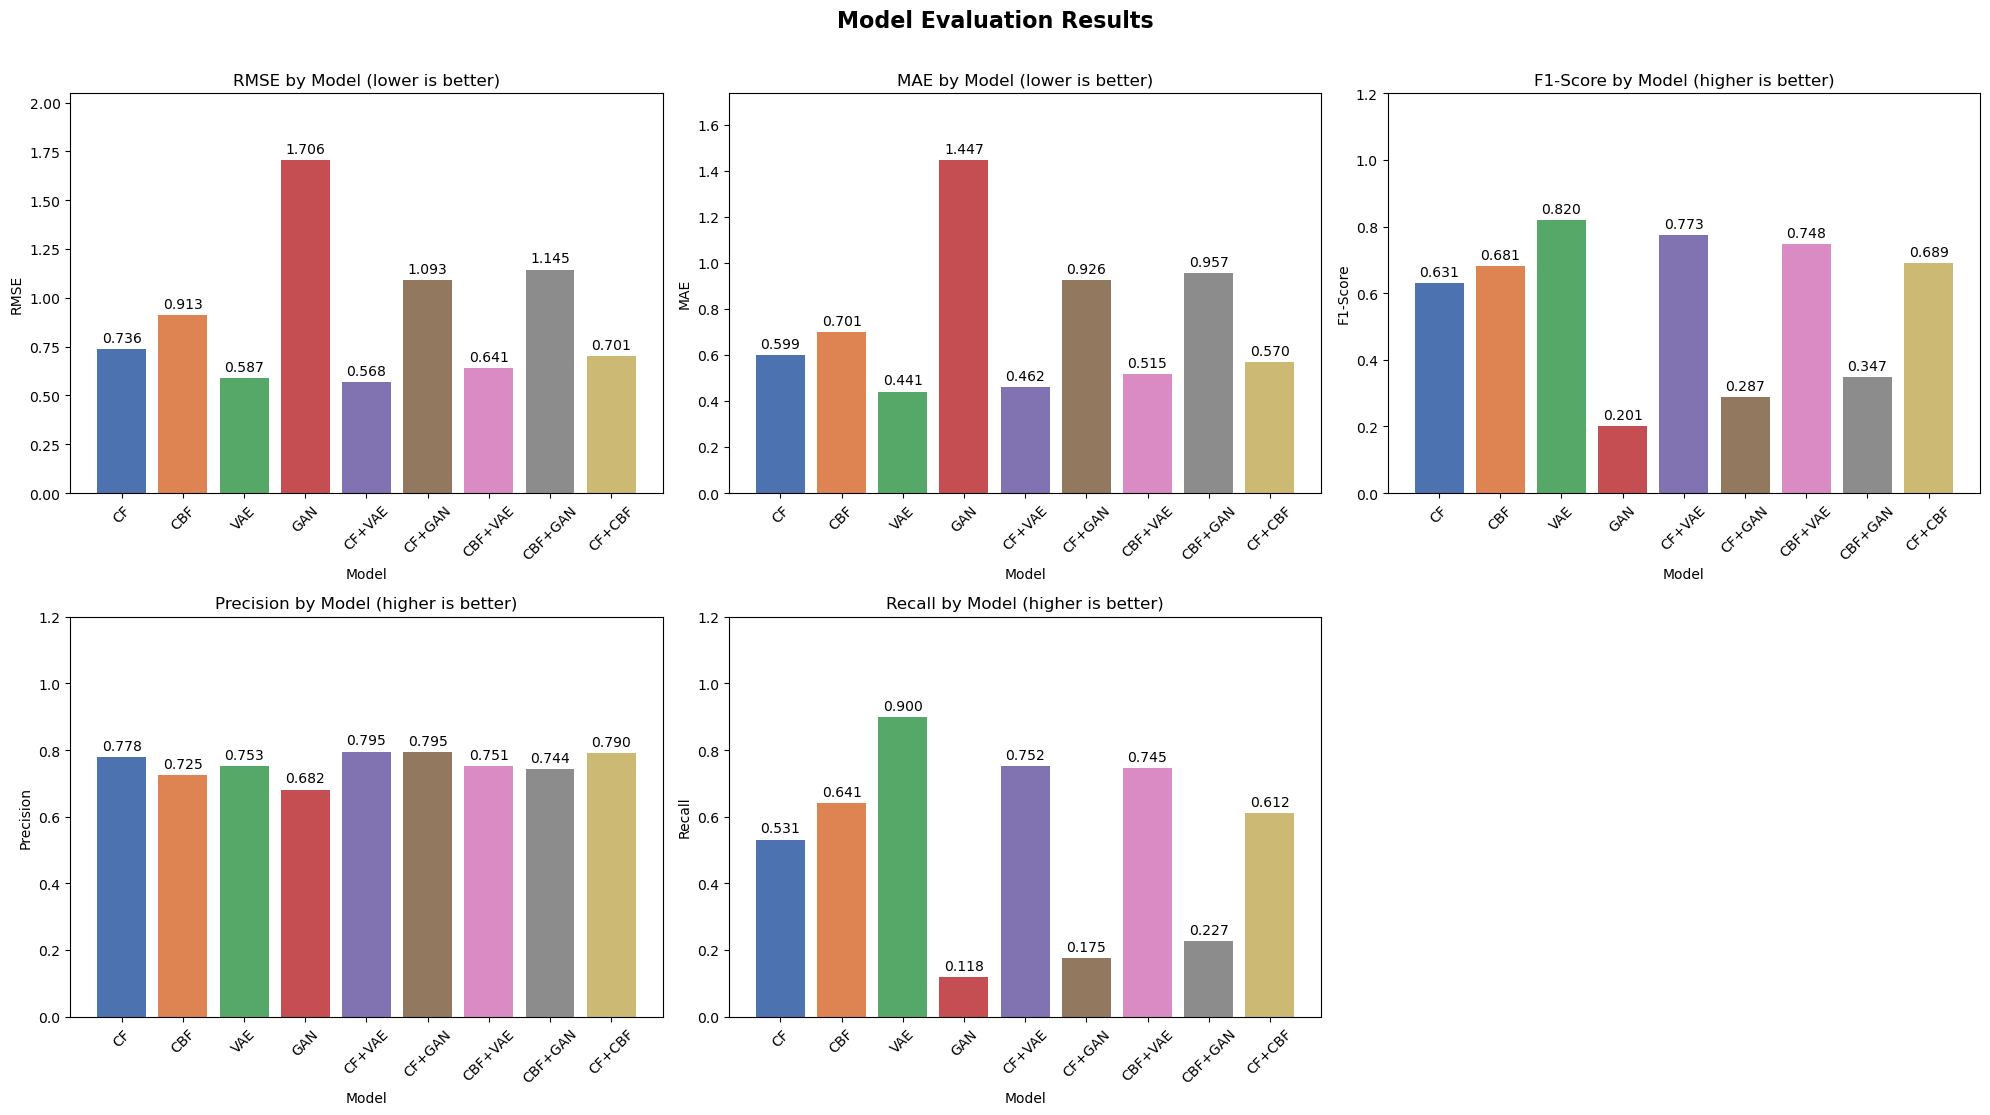

In [64]:
# ── Evaluation Results Visualization ──────────────────────────────────────────
eval_df_plot = eval_df.set_index('Model')
models = eval_df_plot.index.tolist()
colors = ['#4C72B0', '#DD8452', '#55A868', '#C44E52', '#8172B2', '#937860', '#DA8BC3', '#8C8C8C', '#CCB974']

fig, axes = plt.subplots(2, 3, figsize=(20, 11))
fig.suptitle('Model Evaluation Results', fontsize=16, fontweight='bold', y=1.01)

# 1. RMSE Comparison
ax1 = axes[0, 0]
bars = ax1.bar(models, eval_df_plot['RMSE'], color=colors)
ax1.bar_label(bars, fmt='%.3f', padding=3)
ax1.set_title('RMSE by Model (lower is better)')
ax1.set_xlabel('Model')
ax1.set_ylabel('RMSE')
ax1.set_ylim(0, eval_df_plot['RMSE'].max() * 1.2)
ax1.tick_params(axis='x', rotation=45)

# 2. MAE Comparison
ax2 = axes[0, 1]
bars = ax2.bar(models, eval_df_plot['MAE'], color=colors)
ax2.bar_label(bars, fmt='%.3f', padding=3)
ax2.set_title('MAE by Model (lower is better)')
ax2.set_xlabel('Model')
ax2.set_ylabel('MAE')
ax2.set_ylim(0, eval_df_plot['MAE'].max() * 1.2)
ax2.tick_params(axis='x', rotation=45)

# 3. F1-Score
ax3 = axes[0, 2]
bars = ax3.bar(models, eval_df_plot['F1-Score'], color=colors)
ax3.bar_label(bars, fmt='%.3f', padding=3)
ax3.set_title('F1-Score by Model (higher is better)')
ax3.set_xlabel('Model')
ax3.set_ylabel('F1-Score')
ax3.set_ylim(0, 1.2)
ax3.tick_params(axis='x', rotation=45)

# 4. Precision
ax4 = axes[1, 0]
bars = ax4.bar(models, eval_df_plot['Precision'], color=colors)
ax4.bar_label(bars, fmt='%.3f', padding=3)
ax4.set_title('Precision by Model (higher is better)')
ax4.set_xlabel('Model')
ax4.set_ylabel('Precision')
ax4.set_ylim(0, 1.2)
ax4.tick_params(axis='x', rotation=45)

# 5. Recall
ax5 = axes[1, 1]
bars = ax5.bar(models, eval_df_plot['Recall'], color=colors)
ax5.bar_label(bars, fmt='%.3f', padding=3)
ax5.set_title('Recall by Model (higher is better)')
ax5.set_xlabel('Model')
ax5.set_ylabel('Recall')
ax5.set_ylim(0, 1.2)
ax5.tick_params(axis='x', rotation=45)

# 6. Hide unused 6th subplot
axes[1, 2].set_visible(False)

plt.tight_layout()
plt.show()

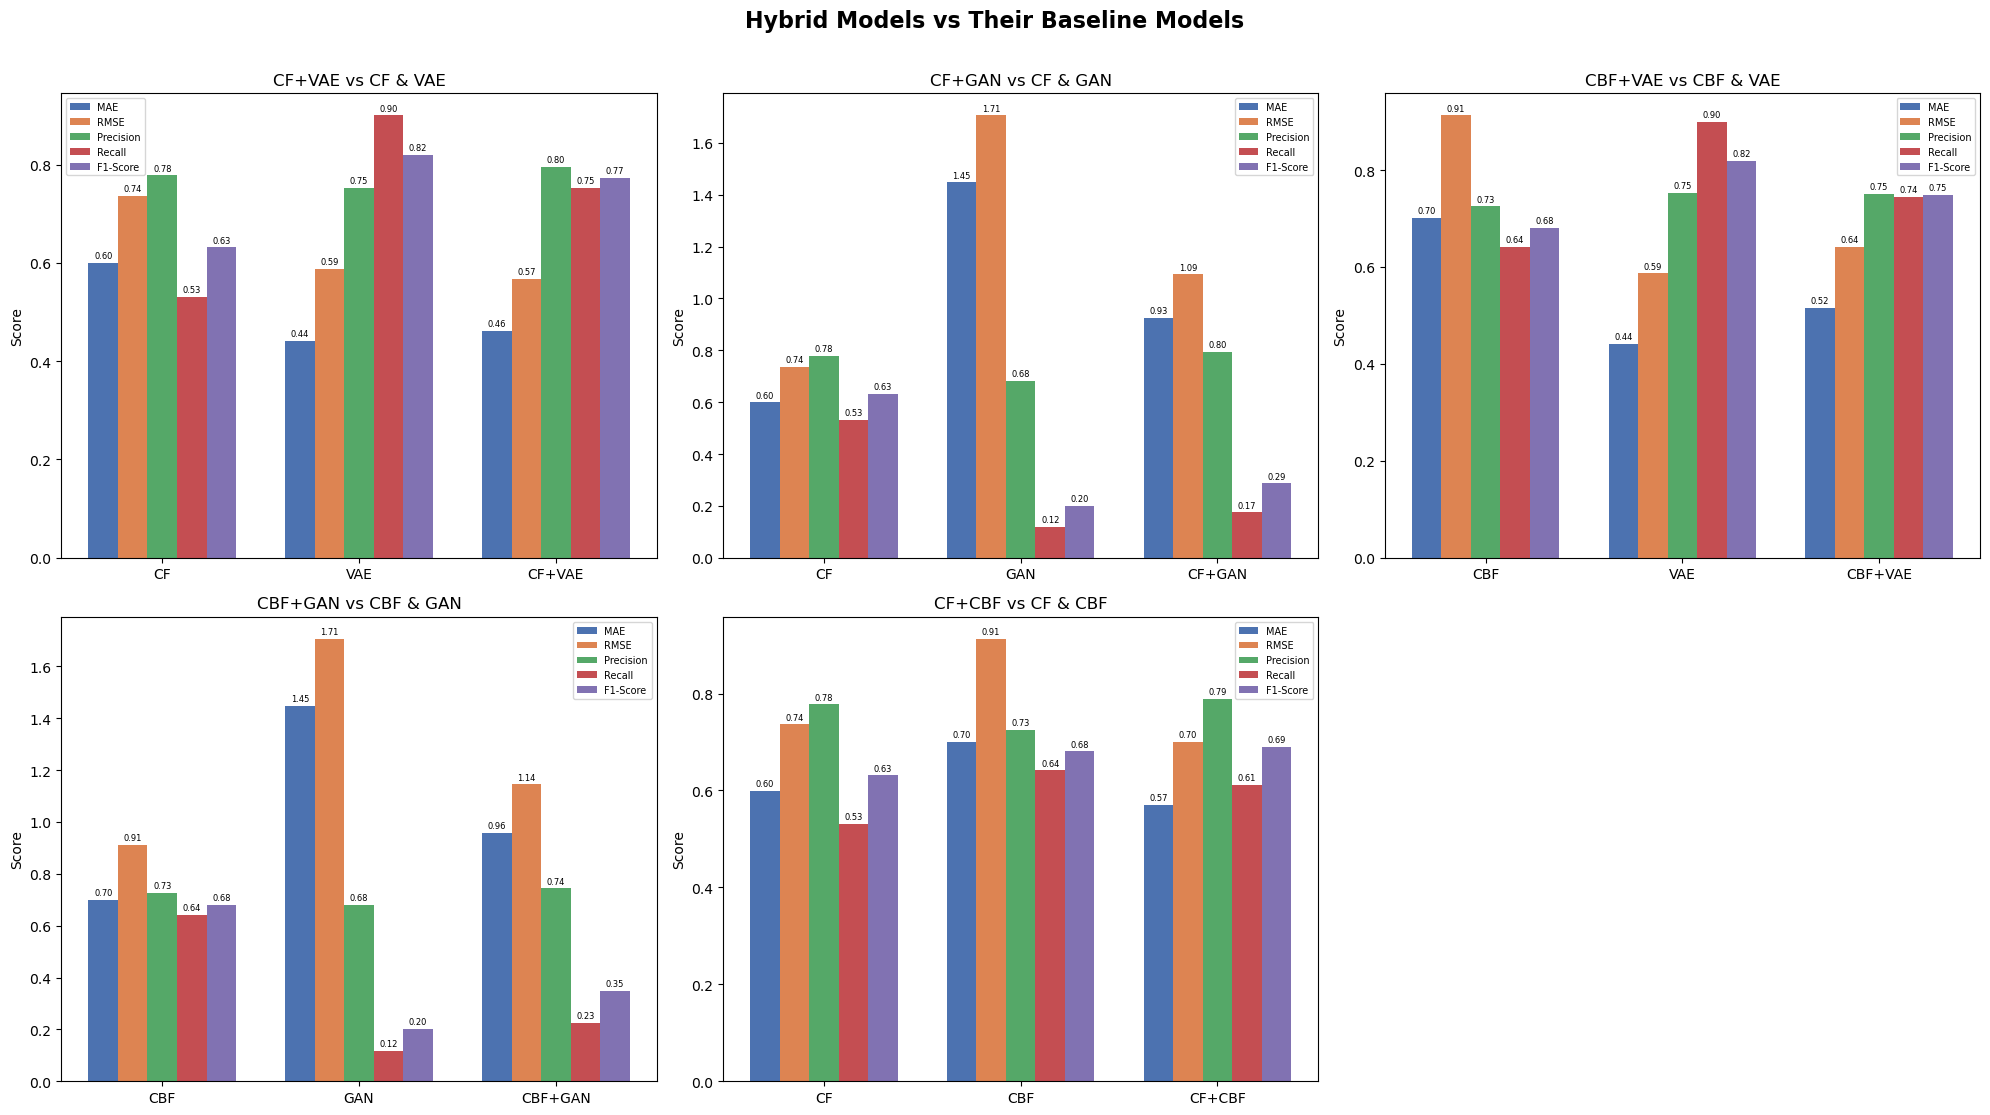

In [65]:
# ── Hybrid vs Baseline Comparison ──────────────────────────────────────────
metrics_to_plot = ['MAE', 'RMSE', 'Precision', 'Recall', 'F1-Score']
metric_colors = ['#4C72B0', '#DD8452', '#55A868', '#C44E52', '#8172B2']

comparison_pairs = [
    ('CF',  'VAE', 'CF+VAE'),
    ('CF',  'GAN', 'CF+GAN'),
    ('CBF', 'VAE', 'CBF+VAE'),
    ('CBF', 'GAN', 'CBF+GAN'),
    ('CF',  'CBF', 'CF+CBF')
]

fig, axes = plt.subplots(2, 3, figsize=(20, 11))
fig.suptitle('Hybrid Models vs Their Baseline Models', fontsize=16, fontweight='bold', y=1.01)
axes_flat = axes.flatten()

for i, (base1, base2, hybrid_name) in enumerate(comparison_pairs):
    ax = axes_flat[i]

    model_names = [base1, base2, hybrid_name]
    x = np.arange(len(model_names))
    width = 0.15

    for j, metric in enumerate(metrics_to_plot):
        vals = eval_df_plot.loc[model_names, metric].values
        offset = (j - (len(metrics_to_plot) - 1) / 2) * width
        bars = ax.bar(x + offset, vals, width, label=metric, color=metric_colors[j])
        ax.bar_label(bars, fmt='%.2f', padding=2, fontsize=6)

    ax.set_xticks(x)
    ax.set_xticklabels(model_names)
    ax.set_title(f'{hybrid_name} vs {base1} & {base2}')
    ax.set_ylabel('Score')
    ax.legend(fontsize=7)

# Hide unused 6th subplot
axes_flat[5].set_visible(False)

plt.tight_layout()
plt.show()

## Extract Cleaned Dataset & Trained Hybrid Model

In [67]:
EXPORT_DATA_DIR = "data"
EXPORT_MODEL_DIR = "models"
os.makedirs(EXPORT_DATA_DIR, exist_ok=True)
os.makedirs(EXPORT_MODEL_DIR, exist_ok=True)

# ----------------------------------------------------------------------
# 1. Cleaned datasets
# ----------------------------------------------------------------------
member_clean.to_csv(os.path.join(EXPORT_DATA_DIR, "member_clean.csv"), index=False)
program_clean.to_csv(os.path.join(EXPORT_DATA_DIR, "program_clean.csv"), index=False)
interactions_df.to_csv(os.path.join(EXPORT_DATA_DIR, "interactions_df.csv"), index=False)
user_item_matrix.to_csv(os.path.join(EXPORT_DATA_DIR, "user_item_matrix.csv"))

# label_encoders holds the Gender / Workout_Type encoders fit during member cleaning;
# le_level / le_goal hold the level / goal encoders fit during program cleaning.
all_encoders = dict(label_encoders)
all_encoders['level'] = le_level
all_encoders['goal'] = le_goal
with open(os.path.join(EXPORT_DATA_DIR, "encoders.pkl"), "wb") as f:
    pickle.dump(all_encoders, f)

# ----------------------------------------------------------------------
# 2. Collaborative Filtering (pure numpy/pandas -> plain pickle)
# ----------------------------------------------------------------------
with open(os.path.join(EXPORT_MODEL_DIR, "cf_model.pkl"), "wb") as f:
    pickle.dump(cf_model, f)

# ----------------------------------------------------------------------
# 3. Content-Based Filtering (pure numpy/pandas -> plain pickle)
# ----------------------------------------------------------------------
with open(os.path.join(EXPORT_MODEL_DIR, "cbf_model.pkl"), "wb") as f:
    pickle.dump(cbf_model, f)

# ----------------------------------------------------------------------
# 4. VAE (Keras sub-models saved natively; wrapper class is not pickled)
# ----------------------------------------------------------------------
vae_model.encoder.save(os.path.join(EXPORT_MODEL_DIR, "vae_encoder.keras"))
vae_model.decoder.save(os.path.join(EXPORT_MODEL_DIR, "vae_decoder.keras"))
with open(os.path.join(EXPORT_MODEL_DIR, "vae_meta.pkl"), "wb") as f:
    pickle.dump(
        {"input_dim": vae_model.input_dim, "latent_dim": vae_model.latent_dim, "hidden_dims": vae_model.hidden_dims},
        f,
    )

# ----------------------------------------------------------------------
# 5. GAN (Keras sub-models saved natively; wrapper class is not pickled)
# ----------------------------------------------------------------------
gan_model.generator.save(os.path.join(EXPORT_MODEL_DIR, "gan_generator.keras"))
gan_model.discriminator.save(os.path.join(EXPORT_MODEL_DIR, "gan_discriminator.keras"))
with open(os.path.join(EXPORT_MODEL_DIR, "gan_meta.pkl"), "wb") as f:
    pickle.dump(
        {"input_dim": gan_model.input_dim, "latent_dim": gan_model.latent_dim, "hidden_dim": gan_model.hidden_dim},
        f,
    )

print(f"Saved cleaned datasets to '{EXPORT_DATA_DIR}/'")
print(f"Saved CF, CBF, VAE, and GAN models to '{EXPORT_MODEL_DIR}/'")
print(f"Reference users: {user_item_matrix.shape[0]}, programs: {user_item_matrix.shape[1]}")


Saved cleaned datasets to 'data/'
Saved CF, CBF, VAE, and GAN models to 'models/'
Reference users: 1652, programs: 1754
